# Лабораторна робота № 7
## Амплітудні перетворення, вирівнювання гістограми та бінаризація за методом Оцу

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy, OpenCV (`cv2`), Pillow, Matplotlib

## 1. Мета роботи

Дослідити точкові (амплітудні) перетворення півтонових зображень: побудувати гістограму та функцію розподілу, виконати лінійне контрастування та гамма-корекцію за таблицями підстановки (LUT), провести глобальне вирівнювання гістограми та порівняти фіксований поріг, метод Оцу й адаптивну бінаризацію на зображенні з нерівномірним освітленням.

## 2. Основні співвідношення

- Точкова операція: вихідний піксель $s = T(r)$ залежить лише від вхідного пікселя $r$ у тих самих координатах; для 8-бітного зображення $r, s \in [0, 255]$.
- Лінійне контрастування: $s = \mathrm{clip}(k r + b, 0, 255)$, де $k$ задає контраст (нахил), $b$ — яскравість (зсув).
- Гамма-корекція: $s = 255 \left(\dfrac{r}{255}\right)^{\gamma}$. При $\gamma < 1$ темні тони світлішають, при $\gamma > 1$ зображення темнішає, а деталі у світлих областях стають помітнішими. Реалізується таблицею з 256 значень (LUT).
- Гістограма $h(r_k) = n_k$, нормована $p(r_k) = \dfrac{n_k}{M N}$, функція розподілу $\mathrm{CDF}(k) = \sum\limits_{j \le k} p(r_j)$.
- Вирівнювання гістограми: $s_k = (L - 1) \sum\limits_{j \le k} p(r_j)$, $L = 256$; розподіл яскравості наближається до рівномірного, контраст зростає.
- Метод Оцу: поріг $T$ вибирається з умови максимуму міжкласової дисперсії $\sigma_B^2(T) = \omega_0 \omega_1 (\mu_0 - \mu_1)^2$, де $\omega_{0,1}$ — імовірності класів, $\mu_{0,1}$ — їхні середні. Найкраще працює для двомодальної гістограми.
- Адаптивний поріг: $T(x, y) = \mathrm{LocalMean}_{S \times S}(x, y) - C$ ($S$ непарне, $C$ — постійний зсув); середнє може бути рівномірним або гаусовим.

## 3. Індивідуальне завдання (варіант 2)

| Тип зображення | $k$, $b$ | $\gamma_1$, $\gamma_2$ | $T_{fixed}$ | $S$, $C$ |
|---|---|---|---|---|
| МРТ головного мозку | 1.8; −40 | 0.40; 2.5 | 95 | 15; 4 |

Аналітичний розрахунок:

- лінійне перетворення $s = 1.8 r - 40$: $s = 0$ при $r \le 40 / 1.8 = 22.2$, $s = 255$ при $r \ge 295 / 1.8 = 163.9$, тобто на $[0, 255]$ відображається лише інтервал вхідних рівнів $22.2 \ldots 163.9$ (розтягнення в 1.8 рази, найтемніші пікселі відсікаються);
- гамма-корекція: для $\gamma_1 = 0.40$ рівень $r = 50$ переходить у $255 (50 / 255)^{0.4} \approx 133$ (різке підсвічування тіней), для $\gamma_2 = 2.5$ рівень $r = 100$ переходить у $255 (100 / 255)^{2.5} \approx 25$ (затемнення);
- вікно адаптивного порога $S = 15$ ($15 \times 15 = 225$ пікселів), зсув $C = 4$ рівня: піксель стає білим, якщо він яскравіший за локальне середнє мінус 4;
- вхідне зображення. Знімка МРТ у завданні немає, тому я згенерував синтетичний фантом (512 × 512): череп, сіра та біла речовина, два шлуночки, три яскраві осередки, нерівномірне освітлення (ліва частина темніша за праву приблизно у 1.8 разів: коефіцієнт підсилення від 0.65 до 1.15) та гаусів шум із $\sigma = 3$. Динамічний діапазон навмисно вузький.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab7_amplitude_processing.py`. Графіки зберігаються в каталог `figures/`, вхідне зображення — у `data/`.

### Блок 1. Підготовка середовища, імпорт та генерація низькоконтрастної сцени

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# каталоги для графіків і даних
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

# параметри варіанта 2
K_LIN, B_LIN = 1.8, -40       # лінійне перетворення s = k*r + b
GAMMA_1, GAMMA_2 = 0.40, 2.5  # гамма-корекція: g1 < 1 та g2 > 1
T_FIXED = 95                  # фіксований поріг
S_WIN, C_OFFSET = 15, 4       # вікно та зсув адаптивного порога


def generate_brain_mri_phantom(size=512, seed=3):
    """
    Імітація низькоконтрастного знімка МРТ головного мозку: череп, сіра та
    біла речовина, шлуночки, кілька яскравих осередків, нерівномірне
    освітлення (чутливість котушки) та шум. Повертає зображення uint8 та
    маску внутрішньої області мозку.
    """
    rng = np.random.default_rng(seed)
    c = size // 2
    img = np.full((size, size), 10, dtype=np.float32)          # повітря

    cv2.ellipse(img, (c, c), (215, 240), 0, 0, 360, 60, -1)    # м'які тканини голови
    cv2.ellipse(img, (c, c), (195, 220), 0, 0, 360, 25, -1)    # череп
    brain_mask = np.zeros((size, size), dtype=np.uint8)
    cv2.ellipse(brain_mask, (c, c), (178, 202), 0, 0, 360, 255, -1)
    cv2.ellipse(img, (c, c), (178, 202), 0, 0, 360, 85, -1)    # сіра речовина
    cv2.ellipse(img, (c, c), (140, 168), 0, 0, 360, 105, -1)   # біла речовина
    cv2.ellipse(img, (c - 28, c - 10), (22, 55), 10, 0, 360, 35, -1)  # шлуночки
    cv2.ellipse(img, (c + 28, c - 10), (22, 55), -10, 0, 360, 35, -1)
    for (x, y, r) in [(c - 85, c + 70, 16), (c + 95, c + 40, 12), (c + 60, c - 100, 10)]:
        cv2.circle(img, (x, y), r, 125, -1)                    # яскраві осередки

    img = cv2.GaussianBlur(img, (0, 0), 1.6)

    # нерівномірне підсилення: ліва частина темніша за праву
    xx, yy = np.meshgrid(np.arange(size), np.arange(size))
    bias = 0.65 + 0.5 * xx / (size - 1) - 0.08 * ((yy - c) / c) ** 2
    img = img * bias + rng.normal(0, 3.0, img.shape)
    return np.clip(img, 0, 255).astype(np.uint8), brain_mask


scene, brain_mask = generate_brain_mri_phantom()
cv2.imwrite("data/low_contrast_input.png", scene)
print("Вхідне зображення збережено: data/low_contrast_input.png")

Вхідне зображення збережено: data/low_contrast_input.png


### Блок 2. Гістограма, функція розподілу та статистичні характеристики

--- ГІСТОГРАМА ВХІДНОГО ЗОБРАЖЕННЯ ---
Розмір: (512, 512), тип: uint8
cv2.calcHist і np.histogram збігаються: True
Діапазон яскравості: 0..134 (динамічний діапазон 134)
Середнє = 45.95, СКВ = 36.24
Мінімальний рівень з ненульовою частотою: 0, рівень, що охоплює 99 % пікселів: 108


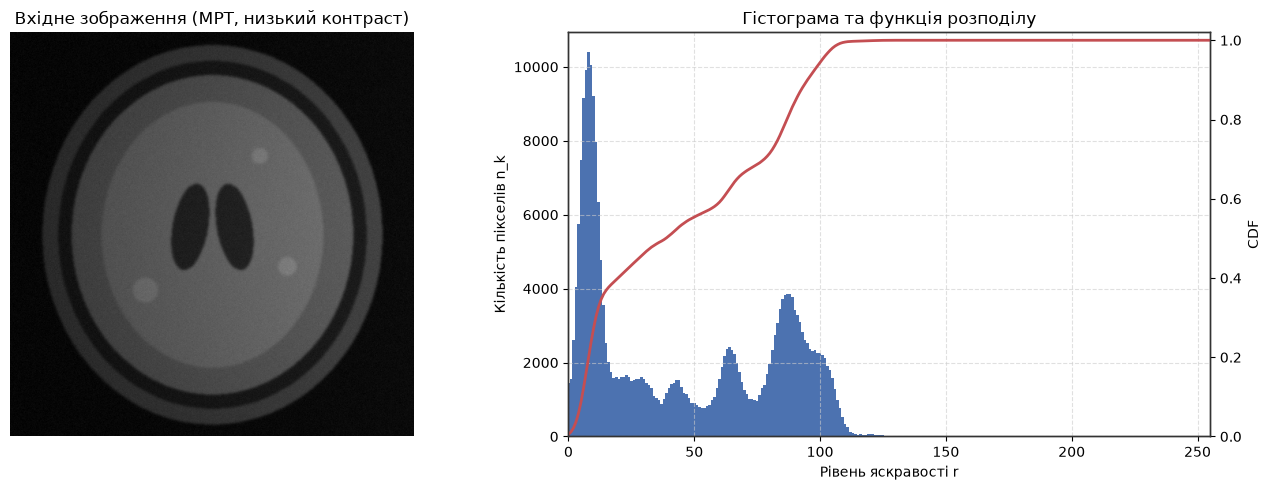

In [2]:
img = cv2.imread("data/low_contrast_input.png", cv2.IMREAD_GRAYSCALE)

hist_cv = cv2.calcHist([img], [0], None, [256], [0, 256]).ravel()
hist_np, _ = np.histogram(img, bins=256, range=(0, 256))
pdf = hist_np / img.size
cdf = np.cumsum(pdf)


def image_stats(a):
    """Діапазон, середнє та СКВ яскравості зображення."""
    return int(a.min()), int(a.max()), float(a.mean()), float(a.std())


lo, hi, mean_in, std_in = image_stats(img)
print("--- ГІСТОГРАМА ВХІДНОГО ЗОБРАЖЕННЯ ---")
print(f"Розмір: {img.shape}, тип: {img.dtype}")
print(f"cv2.calcHist і np.histogram збігаються: {np.array_equal(hist_cv.astype(int), hist_np)}")
print(f"Діапазон яскравості: {lo}..{hi} (динамічний діапазон {hi - lo})")
print(f"Середнє = {mean_in:.2f}, СКВ = {std_in:.2f}")
print(f"Мінімальний рівень з ненульовою частотою: {np.nonzero(hist_np)[0][0]}, "
      f"рівень, що охоплює 99 % пікселів: {np.searchsorted(cdf, 0.99)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Вхідне зображення (МРТ, низький контраст)")
axes[0].axis('off')
axes[1].bar(np.arange(256), hist_np, width=1.0, color='#4c72b0')
axes[1].set_xlabel("Рівень яскравості r")
axes[1].set_ylabel("Кількість пікселів n_k")
axes[1].set_title("Гістограма та функція розподілу")
axes[1].set_xlim(0, 255)
axes[1].grid(True)
ax_cdf = axes[1].twinx()
ax_cdf.plot(np.arange(256), cdf, color='#c44e52', linewidth=2)
ax_cdf.set_ylabel("CDF")
ax_cdf.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig("figures/histogram_analysis.png", dpi=300)
plt.show()

**Статистика вхідного зображення:**

| Величина | Значення |
|---|---|
| Розмір, тип | $512 \times 512$, `uint8` |
| Діапазон яскравості | 0 … 134 (динамічний діапазон 134) |
| Середнє / СКВ | 45.95 / 36.24 |
| Рівень, що охоплює 99 % пікселів | 108 |
| `cv2.calcHist` та `np.histogram` | збігаються |

Гістограма займає лише нижню половину шкали (максимум 134 з 255) і має кілька піків: найбільший біля нуля (повітря та череп), далі піки сірої та білої речовини. CDF швидко зростає на початку, бо понад 40 % пікселів — темне тло. Ліва частина кадру через нерівномірність освітлення темніша, тому піки гістограми розмиті.

### Блок 3. Лінійне та гамма-перетворення за допомогою таблиць LUT


--- ЛІНІЙНЕ ТА ГАММА-ПЕРЕТВОРЕННЯ ---
Лінійне: k = 1.8, b = -40; r у [0, 255] -> s у [0, 255] при r від 22.2 до 163.9
Відсічено знизу (s < 0): 41.40 % пікселів, зверху (s > 255): 0.00 %
Зображення                  min   max  діапазон   середнє      СКВ
Вхідне                        0   134       134     45.95    36.24
Лінійне (k=1.8, b=-40)        0   201       201     52.14    55.34
Гамма 0.4                     0   197       197    114.89    47.12
Гамма 2.5                     0    51        51      7.33     9.03


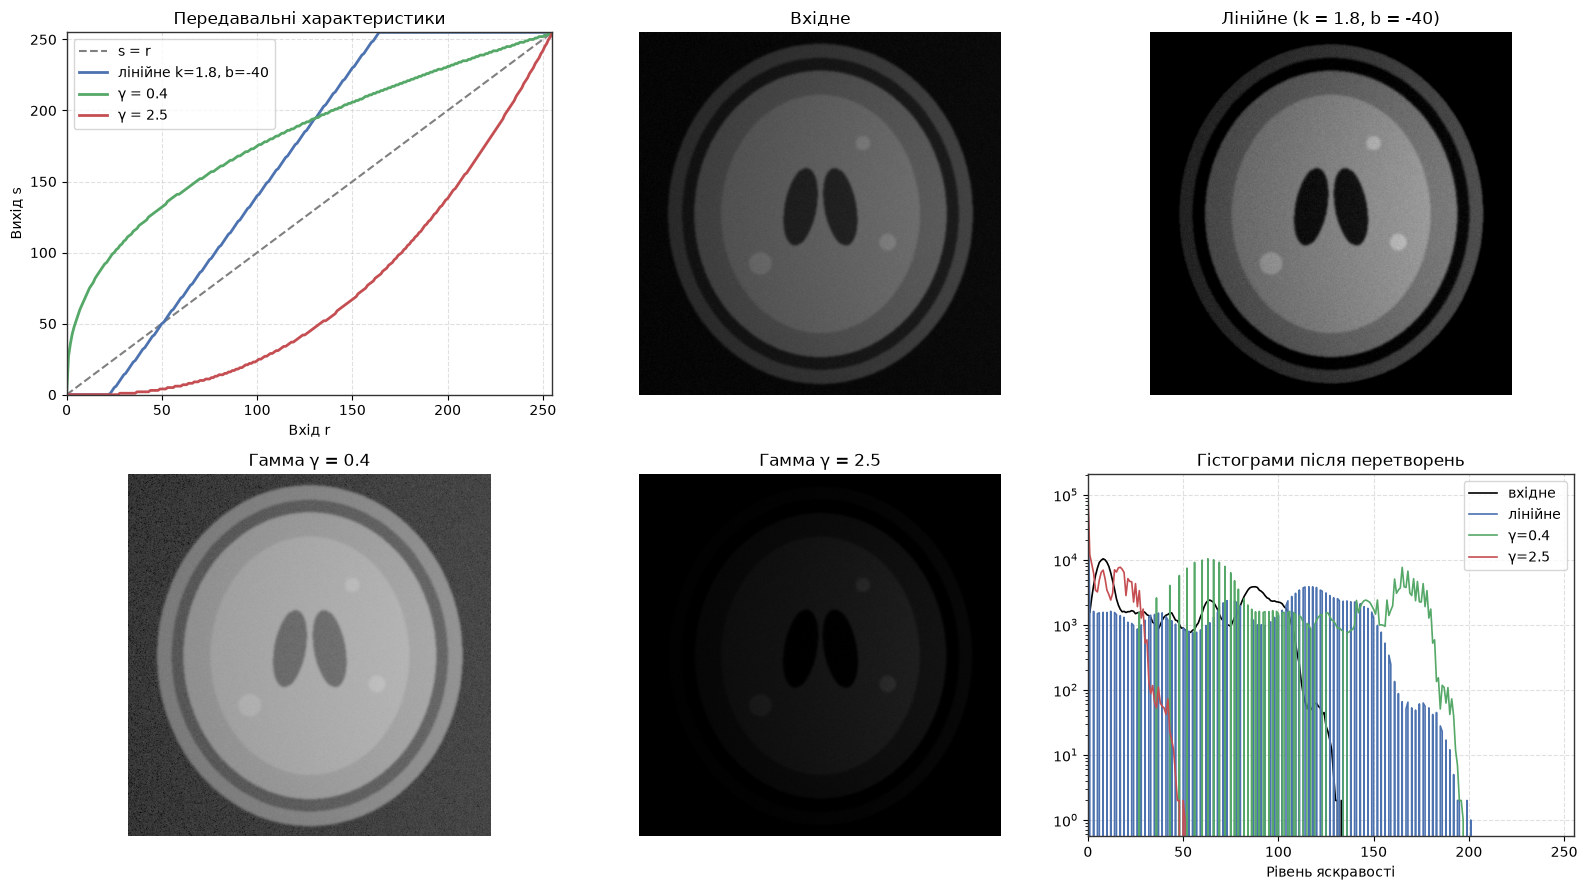

In [3]:
r_levels = np.arange(256)
lut_lin = np.clip(K_LIN * r_levels + B_LIN, 0, 255).astype(np.uint8)
lut_g1 = np.clip(255 * (r_levels / 255.0) ** GAMMA_1, 0, 255).astype(np.uint8)
lut_g2 = np.clip(255 * (r_levels / 255.0) ** GAMMA_2, 0, 255).astype(np.uint8)

img_lin = cv2.LUT(img, lut_lin)
img_g1 = cv2.LUT(img, lut_g1)
img_g2 = cv2.LUT(img, lut_g2)

# яка частка пікселів у лінійному перетворенні втрачена через відсікання
clip_low = 100 * np.mean(K_LIN * img.astype(float) + B_LIN < 0)
clip_high = 100 * np.mean(K_LIN * img.astype(float) + B_LIN > 255)

print("\n--- ЛІНІЙНЕ ТА ГАММА-ПЕРЕТВОРЕННЯ ---")
print(f"Лінійне: k = {K_LIN}, b = {B_LIN}; r у [0, 255] -> s у [0, 255] при r від "
      f"{-B_LIN / K_LIN:.1f} до {(255 - B_LIN) / K_LIN:.1f}")
print(f"Відсічено знизу (s < 0): {clip_low:.2f} % пікселів, зверху (s > 255): {clip_high:.2f} %")
print(f"{'Зображення':<26}{'min':>5}{'max':>6}{'діапазон':>10}{'середнє':>10}{'СКВ':>9}")
for name, a in [("Вхідне", img), (f"Лінійне (k={K_LIN}, b={B_LIN})", img_lin),
                (f"Гамма {GAMMA_1}", img_g1), (f"Гамма {GAMMA_2}", img_g2)]:
    mn, mx, me, sd = image_stats(a)
    print(f"{name:<26}{mn:>5}{mx:>6}{mx - mn:>10}{me:>10.2f}{sd:>9.2f}")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes[0, 0].plot(r_levels, r_levels, '--', color='gray', label="s = r")
axes[0, 0].plot(r_levels, lut_lin, color='#4c72b0', linewidth=2, label=f"лінійне k={K_LIN}, b={B_LIN}")
axes[0, 0].plot(r_levels, lut_g1, color='#55a868', linewidth=2, label=f"γ = {GAMMA_1}")
axes[0, 0].plot(r_levels, lut_g2, color='#c44e52', linewidth=2, label=f"γ = {GAMMA_2}")
axes[0, 0].set_xlabel("Вхід r")
axes[0, 0].set_ylabel("Вихід s")
axes[0, 0].set_title("Передавальні характеристики")
axes[0, 0].set_xlim(0, 255)
axes[0, 0].set_ylim(0, 255)
axes[0, 0].legend(loc='upper left')
axes[0, 0].grid(True)
for ax, a, title in [(axes[0, 1], img, "Вхідне"),
                     (axes[0, 2], img_lin, f"Лінійне (k = {K_LIN}, b = {B_LIN})"),
                     (axes[1, 0], img_g1, f"Гамма γ = {GAMMA_1}"),
                     (axes[1, 1], img_g2, f"Гамма γ = {GAMMA_2}")]:
    ax.imshow(a, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
for a, label, col in [(img, "вхідне", 'black'), (img_lin, "лінійне", '#4c72b0'),
                      (img_g1, f"γ={GAMMA_1}", '#55a868'), (img_g2, f"γ={GAMMA_2}", '#c44e52')]:
    axes[1, 2].plot(np.bincount(a.ravel(), minlength=256), color=col, linewidth=1.2, label=label)
axes[1, 2].set_title("Гістограми після перетворень")
axes[1, 2].set_xlabel("Рівень яскравості")
axes[1, 2].set_xlim(0, 255)
axes[1, 2].set_yscale('log')
axes[1, 2].legend()
axes[1, 2].grid(True)
plt.tight_layout()
plt.savefig("figures/linear_and_gamma_transf.png", dpi=300)
plt.show()

**Статистика після амплітудних перетворень:**

| Зображення | min | max | Діапазон | Середнє | СКВ |
|---|---|---|---|---|---|
| Вхідне | 0 | 134 | 134 | 45.95 | 36.24 |
| Лінійне ($k = 1.8$, $b = -40$) | 0 | 201 | 201 | 52.14 | 55.34 |
| Гамма 0.4 | 0 | 197 | 197 | 114.89 | 47.12 |
| Гамма 2.5 | 0 | 51 | 51 | 7.33 | 9.03 |

Лінійне перетворення розтягує діапазон з 134 до 201 і збільшує СКВ з 36.2 до 55.3 (контраст зріс у 1.5 разів). Рівні $r < 22.2$ відсікаються в нуль: так губиться 41.40 % пікселів (повітря й найтемніший шар черепа), верхнього відсікання немає (0.00 %). Гамма $\gamma_1 = 0.40$ піднімає середнє яскравості з 46 до 115 і робить помітними тканини в тіні (діапазон 197, але СКВ лише 47.1: темні та середні тони стиснуті до верху). Гамма $\gamma_2 = 2.5$ майже затемнює зображення (діапазон 51, середнє 7.3), зате розтягує верхні рівні, тому лінійне перетворення й $\gamma_1$ підходять для темного знімка, а $\gamma_2$ — ні.

### Блок 4. Глобальне вирівнювання гістограми


--- ВИРІВНЮВАННЯ ГІСТОГРАМИ ---
До вирівнювання            діапазон 0..134 (134), середнє 45.95, СКВ 36.24, дисперсія 1313.0
Після (cv2.equalizeHist)   діапазон 0..255 (255), середнє 128.84, СКВ 72.96, дисперсія 5322.8
Максимальна різниця cv2.equalizeHist і PIL.ImageOps.equalize: 9 рівнів
Кількість зайнятих рівнів яскравості: 134 -> 109


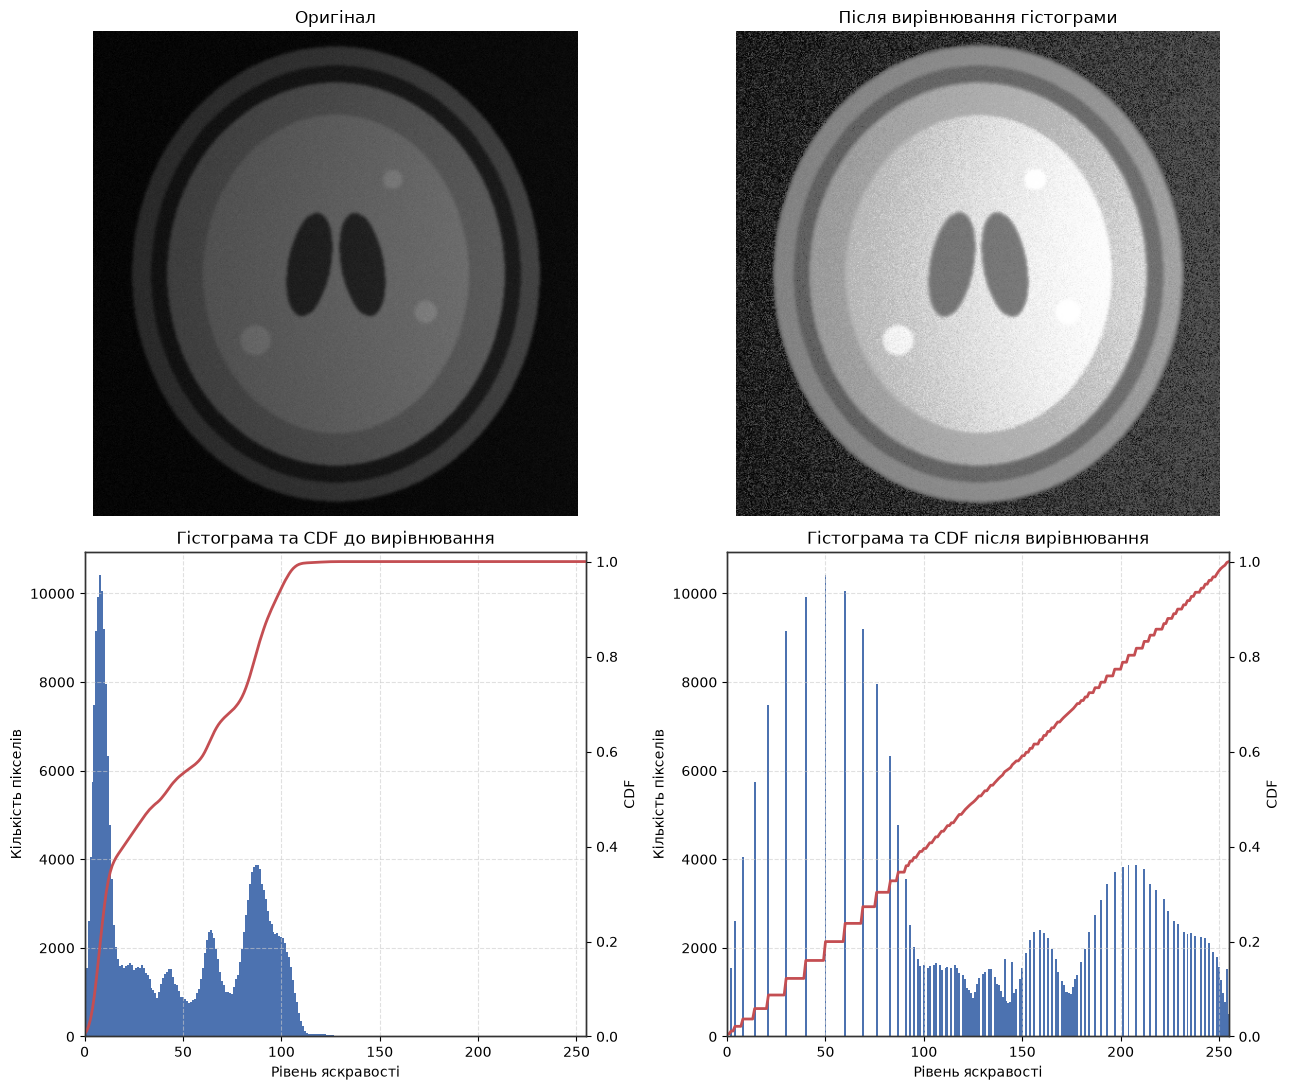

In [4]:
eq_cv = cv2.equalizeHist(img)
eq_pil = np.array(ImageOps.equalize(Image.fromarray(img)))
diff_eq = np.abs(eq_cv.astype(int) - eq_pil.astype(int)).max()

hist_eq = np.bincount(eq_cv.ravel(), minlength=256)
cdf_eq = np.cumsum(hist_eq) / eq_cv.size

print("\n--- ВИРІВНЮВАННЯ ГІСТОГРАМИ ---")
for name, a in [("До вирівнювання", img), ("Після (cv2.equalizeHist)", eq_cv)]:
    mn, mx, me, sd = image_stats(a)
    print(f"{name:<26} діапазон {mn}..{mx} ({mx - mn}), середнє {me:.2f}, СКВ {sd:.2f}, "
          f"дисперсія {sd ** 2:.1f}")
print(f"Максимальна різниця cv2.equalizeHist і PIL.ImageOps.equalize: {diff_eq} рівнів")
print(f"Кількість зайнятих рівнів яскравості: {np.count_nonzero(hist_np)} -> {np.count_nonzero(hist_eq)}")

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Оригінал")
axes[0, 1].imshow(eq_cv, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Після вирівнювання гістограми")
for ax in axes[0]:
    ax.axis('off')
for ax, h_arr, c_arr, title in [(axes[1, 0], hist_np, cdf, "Гістограма та CDF до вирівнювання"),
                                (axes[1, 1], hist_eq, cdf_eq, "Гістограма та CDF після вирівнювання")]:
    ax.bar(np.arange(256), h_arr, width=1.0, color='#4c72b0')
    ax.set_xlim(0, 255)
    ax.set_xlabel("Рівень яскравості")
    ax.set_ylabel("Кількість пікселів")
    ax.set_title(title)
    ax.grid(True)
    twin = ax.twinx()
    twin.plot(np.arange(256), c_arr, color='#c44e52', linewidth=2)
    twin.set_ylim(0, 1.02)
    twin.set_ylabel("CDF")
plt.tight_layout()
plt.savefig("figures/histogram_equalization.png", dpi=300)
plt.show()

**Вирівнювання гістограми:**

| Величина | До | Після (`cv2.equalizeHist`) |
|---|---|---|
| Діапазон | 0 … 134 (134) | 0 … 255 (255) |
| Середнє | 45.95 | 128.84 |
| СКВ | 36.24 | 72.96 |
| Дисперсія | 1313.0 | 5322.8 |
| Кількість зайнятих рівнів | 134 | 109 |

Динамічний діапазон розтягнувся на всю шкалу, дисперсія зросла в 4.05 разів (з 1313.0 до 5322.8), середнє наблизилось до середини шкали (128.84 проти ідеальних 127.5). CDF стала близькою до прямої, хоча гістограма залишилась «гребінчастою»: вирівнювання лише перерозподіляє рівні, нових не створює, тому кількість зайнятих рівнів навіть зменшилась (134 → 109, сусідні рівні зливаються). Реалізації `cv2.equalizeHist` та `PIL.ImageOps.equalize` відрізняються максимум на 9 рівнів: у них різні правила округлення та нормування CDF, але принцип однаковий.

### Блок 5. Порівняння методів бінаризації: фіксований поріг, Оцу, адаптивні


--- БІНАРИЗАЦІЯ ---
Фіксований поріг T = 95; поріг Оцу (cv2) = 49; поріг за власним перебором = 49; max sigma_B^2 = 1121.8
Адаптивна бінаризація: вікно S = 15, зсув C = 4
Метод                           білих, %    зліва в мозку, %   справа в мозку, %
Фіксований поріг                   10.00                2.46               43.66
Оцу                                44.95               92.65               93.51
Адаптивний (середнє)               80.22               85.45               84.88
Адаптивний (Гаус)                  84.59               87.20               87.13


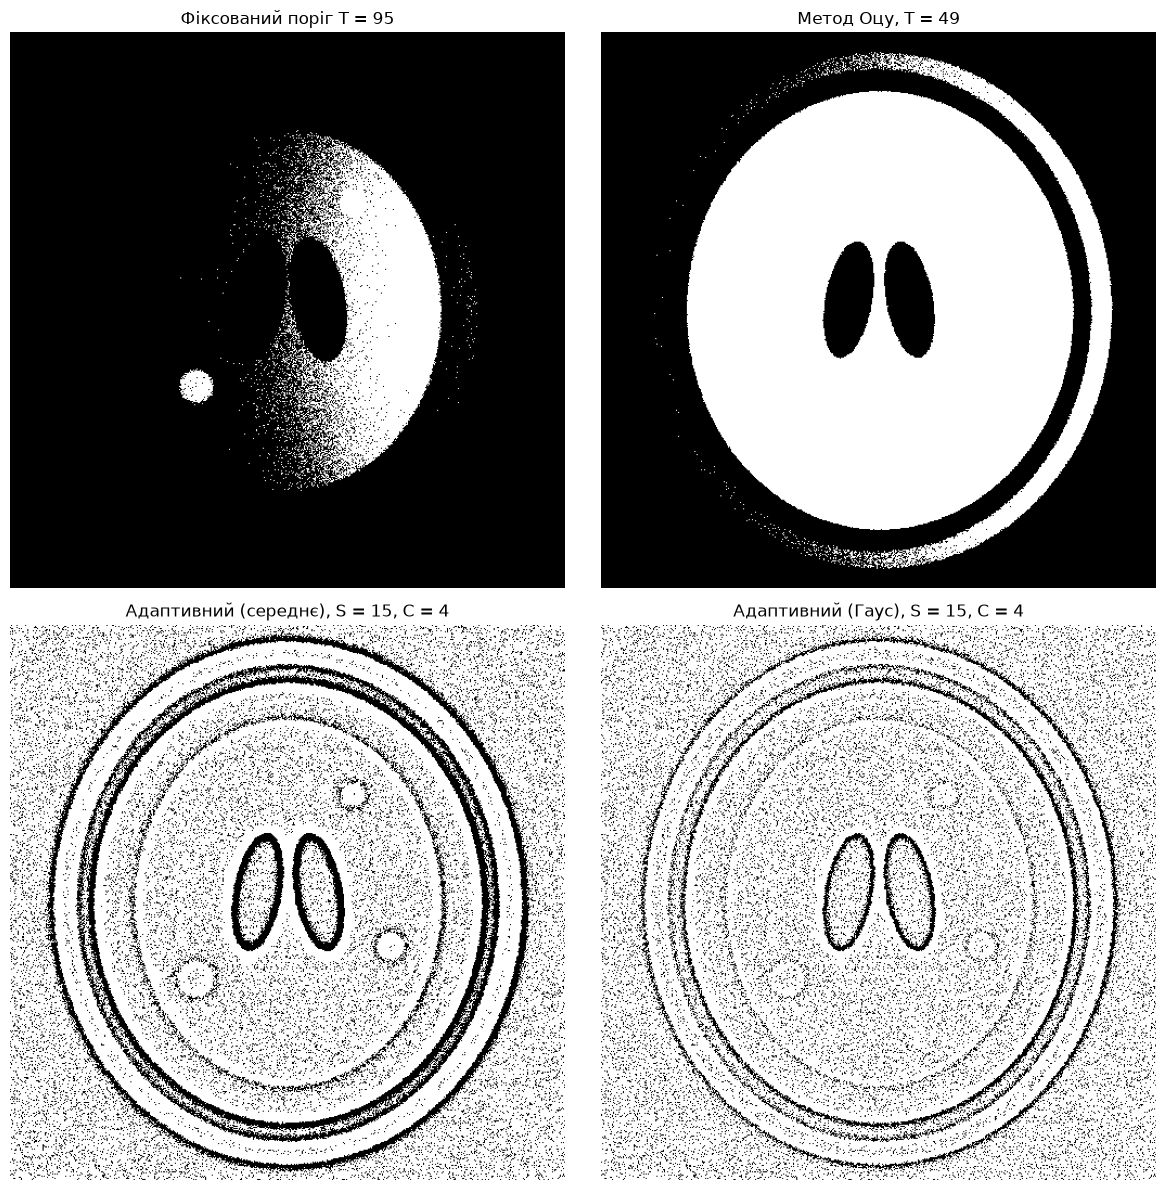


Моделювання завершено. Графіки збережено в 'figures/'.


In [5]:
_, bin_fixed = cv2.threshold(img, T_FIXED, 255, cv2.THRESH_BINARY)
t_otsu, bin_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
bin_mean = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY, S_WIN, C_OFFSET)
bin_gauss = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY, S_WIN, C_OFFSET)

# перевірка критерію Оцу прямим перебором порогів (макс. міжкласова дисперсія)
levels = np.arange(256)
best_t, best_var = 0, -1.0
for t in range(1, 255):
    w0 = pdf[:t + 1].sum()
    w1 = 1.0 - w0
    if w0 == 0 or w1 == 0:
        continue
    mu0 = (levels[:t + 1] * pdf[:t + 1]).sum() / w0
    mu1 = (levels[t + 1:] * pdf[t + 1:]).sum() / w1
    var_b = w0 * w1 * (mu0 - mu1) ** 2
    if var_b > best_var:
        best_t, best_var = t, var_b


def white_share(bw, region):
    """Частка білих пікселів у заданій області."""
    return 100 * np.count_nonzero(bw[region]) / np.count_nonzero(region)


cols = np.arange(img.shape[1])
left = (brain_mask > 0) & (cols[None, :] < img.shape[1] // 2)
right = (brain_mask > 0) & (cols[None, :] >= img.shape[1] // 2)

print("\n--- БІНАРИЗАЦІЯ ---")
print(f"Фіксований поріг T = {T_FIXED}; поріг Оцу (cv2) = {t_otsu:.0f}; "
      f"поріг за власним перебором = {best_t}; max sigma_B^2 = {best_var:.1f}")
print(f"Адаптивна бінаризація: вікно S = {S_WIN}, зсув C = {C_OFFSET}")
print(f"{'Метод':<30}{'білих, %':>10}{'зліва в мозку, %':>20}{'справа в мозку, %':>20}")
for name, bw in [("Фіксований поріг", bin_fixed), ("Оцу", bin_otsu),
                 ("Адаптивний (середнє)", bin_mean), ("Адаптивний (Гаус)", bin_gauss)]:
    print(f"{name:<30}{100 * np.count_nonzero(bw) / bw.size:>10.2f}"
          f"{white_share(bw, left):>20.2f}{white_share(bw, right):>20.2f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, bw, title in [(axes[0, 0], bin_fixed, f"Фіксований поріг T = {T_FIXED}"),
                      (axes[0, 1], bin_otsu, f"Метод Оцу, T = {t_otsu:.0f}"),
                      (axes[1, 0], bin_mean, f"Адаптивний (середнє), S = {S_WIN}, C = {C_OFFSET}"),
                      (axes[1, 1], bin_gauss, f"Адаптивний (Гаус), S = {S_WIN}, C = {C_OFFSET}")]:
    ax.imshow(bw, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/binarization_methods.png", dpi=300)
plt.show()

print("\nМоделювання завершено. Графіки збережено в 'figures/'.")

**Результати бінаризації:**

| Метод | Поріг | Білих, % | Білих у мозку зліва, % | Білих у мозку справа, % |
|---|---|---|---|---|
| Фіксований поріг | $T = 95$ | 10.00 | 2.46 | 43.66 |
| Метод Оцу | $T = 49$ | 44.95 | 92.65 | 93.51 |
| Адаптивний, середнє | $S = 15$, $C = 4$ | 80.22 | 85.45 | 84.88 |
| Адаптивний, Гаус | $S = 15$, $C = 4$ | 84.59 | 87.20 | 87.13 |

Поріг Оцу (cv2) та поріг за власним перебором максимуму $\sigma_B^2$ збігаються ($T = 49$, $\sigma_B^2 = 1121.8$). Фіксований поріг $T = 95$ дуже залежить від освітлення: у правій половині мозку він пропускає 43.66 % пікселів, а в лівій (темнішій) лише 2.46 %, тобто ту саму тканину класифікує по-різному. Метод Оцу вибирає глобальний поріг 49, що відокремлює тканину мозку (сіру й білу речовину) від повітря, черепа та шлуночків і майже не залежить від сторони (92.65 % проти 93.51 %), проте він не відділяє сірої речовини від білої і не виявляє осередків. Адаптивні методи рахують поріг локально, тому частки білого зліва та справа майже однакові (85.45 % та 84.88 %): вони не залежать від градієнта освітлення і підкреслюють межі структур (контури шлуночків, череп, осередки). Але в однорідних областях, де $C = 4$ порівнянний з шумом ($\sigma = 3$), з'являється дрібна «крупа» чорних точок; гаусове усереднення дає трохи менше шуму (84.59 % білих проти 80.22 %), але повільніше за рівномірне.

## 5. Висновки

1. Вхідний знімок МРТ має вузький діапазон яскравості (0 … 134, СКВ 36.24) і нерівномірне освітлення. Лінійне перетворення $s = 1.8 r - 40$ розтягує діапазон до 0 … 201 і збільшує СКВ до 55.34, але відсікає 41.40 % найтемніших пікселів.

2. Гамма-корекція з $\gamma_1 = 0.40$ піднімає середню яскравість з 45.95 до 114.89 і виявляє деталі в тінях; $\gamma_2 = 2.5$ затемнює зображення (середнє 7.33) і придатна лише для світлих знімків. Реалізація через таблицю LUT потребує 256 обчислень замість обчислення степеня для кожного пікселя.

3. Вирівнювання гістограми розтягує діапазон на 0 … 255 і збільшує дисперсію в 4.05 разів, а CDF стає майже лінійною. Кількість зайнятих рівнів не зростає (134 → 109), тому гістограма залишається «гребінчастою», а шум також підсилюється.

4. Фіксований поріг $T = 95$ непридатний для зображення з нерівномірним освітленням: частка білих пікселів у лівій та правій половинах мозку відрізняється у 17.7 разів (2.46 % проти 43.66 %). Метод Оцу ($T = 49$) дає стабільний результат, але лише для грубого поділу «тканина мозку — решта». Адаптивний поріг ($S = 15$, $C = 4$) не залежить від градієнта освітлення, проте за малих $C$ у плоских областях виникає шумова «крупа».

5. Вибір методу залежить від задачі: для двомодальної гістограми й рівномірного освітлення — Оцу; для градієнтного тла — адаптивний поріг, бажано з попереднім згладжуванням або більшим $C$. Результати отримано на синтетичному фантомі, а не на реальному знімку МРТ.

## Відповідь на контрольні питання

**1. Що таке амплітудне перетворення зображення, і чому воно належить до класу поелементних (точкових) операцій у просторовій області?**

* **Визначення амплітудного (градаційного) перетворення:** Це зміна значень яскравості (інтенсивності) пікселів зображення за допомогою функціонального відображення $s = T(r)$, де $r$ — початкове значення яскравості вхідного пікселя, $s$ — нове значення яскравості вихідного пікселя, а $T$ — передавальна функція перетворення.
* **Належність до поелементних (точкових) операцій:** У просторовій області обробка виражається формулою $g(x, y) = T[f(x, y)]$, де розмір просторового околу становить $1 \times 1$ піксель. Нове значення яскравості в точці з координатами $(x, y)$ залежить **виключно від інтенсивності пікселя в цій самій точці** і жодним чином не враховує значення сусідніх пікселів чи їхні просторові координати.

---

**2. Яким чином вибір коефіцієнтів $k$ та $b$ у лінійній передавальній функції $s = k \cdot r + b$ впливає на контрастність і яскравість зображення?**

* **Коефіцієнт нахилу $k$ (підсилення / gain) керує контрастністю:**
* **$k > 1$** — розтягує динамічний діапазон яскравостей, збільшуючи різницю між світлими та темними ділянками (**підвищення контрастності**);
* **$0 < k < 1$** — стискає діапазон яскравостей, роблячи переходи між тонами менш виразними (**зниження контрастності**);
* **$k = 1$** — залишає контрастність незмінною;
* **$k < 0$** (зокрема $k = -1, \, b = L - 1$) — інвертує шкалу яскравості, перетворюючи зображення на **негатив**.


* **Коефіцієнт зміщення $b$ (offset / bias) керує загальною яскравістю:**
* **$b > 0$** — зсуває всі рівні інтенсивності вгору на величину $b$, **висвітлюючи** все зображення;
* **$b < 0$** — зсуває рівні інтенсивності вниз, **затемнюючи** зображення.
*(Примітка: значення, що виходять за межі робочого діапазону $[0, L - 1]$, обмежуються граничними значеннями — відбувається кліпінг у чорний або білий колір).*



---

**3. У чому полягає фізичний та математичний зміст нелінійної гамма-корекції, і за яких значень $\gamma$ відбувається висвітлення темних деталей сцени?**

* **Математичний зміст:** Гамма-корекція описується степеневою функцією:

$$s = c \cdot r^{\gamma}$$



де $r, s \in [0, 1]$ — нормовані значення вхідної та вихідної яскравості (зазвичай $c = 1$), а $\gamma > 0$ — показник степеня. На відміну від лінійного перетворення, крива фіксує крайні точки $(0, 0)$ та $(1, 1)$, але нелінійно розтягує одну частину тонального діапазону за рахунок стиснення іншої без втрати даних через обрізання.
* **Фізичний зміст:** Вона виконує дві ключові ролі:
1. Компенсує нелінійну передавальну характеристику пристроїв відображення та реєстрації (зокрема, у ЕПТ-моніторах світловий потік був пропорційний напрузі у степені $\gamma \approx 2.2$).
2. Узгоджує цифрове кодування з нелінійною (близькою до логарифмічної/степеневої, за законом Вебера-Фехнера) чутливістю людського зору, який значно краще розрізняє градації в темних тонах, ніж у яскравих.


* **Умова висвітлення темних деталей сцени:** Висвітлення тіней відбувається за значень **$0 < \gamma < 1$** (наприклад, $\gamma = 0.4$ або $\gamma = 1 / 2.2 \approx 0.45$). У цьому випадку крива є опуклою вгору і має крутий нахил поблизу $r = 0$, завдяки чому вузький діапазон темних вхідних значень розтягується на широкий діапазон світліших вихідних градацій, проявляючи деталі в тінях, тоді як світлі ділянки м'яко стискаються.

---

**4. Для чого при програмній реалізації нелінійних амплітудних перетворень застосовують таблиці пошуку (Look-Up Table — LUT)?**

* **Прискорення обчислень за рахунок усунення повторних розрахунків:** Нелінійні амплітудні перетворення (гамма-корекція, логарифмічне чи сигмоїдне стиснення) потребують ресурсоємних операцій з рухомою комою (`pow()`, `log()`, `exp()`) для кожного пікселя. Оскільки кількість дискретних рівнів яскравості є обмеженою (наприклад, для 8-бітного зображення $r \in \{0, 1, \dots, 255\}$, усього $256$ можливих значень), функцію $s = T(r)$ обчислюють **лише один раз** для всіх $256$ рівнів і зберігають у одновимірному масиві `LUT[256]`.
* **Заміна математики індексацією пам'яті ($\mathcal{O}(1)$):** Під час обробки всього кадру розміром $M \times N$ (мільйони пікселів) замість обчислення складної формули виконується миттєва підстановка значення з масиву за індексом: `output[y, x] = LUT[input[y, x]]`. Це забезпечує максимальну швидкодію (критично важливу для відеопотоку в реальному часі) і робить час обробки зображення повністю незалежним від математичної складності кривої перетворення.

---

**5. Як визначається гістограма яскравості зображення, і яким чином за її формою можна зробити висновок про динамічний діапазон та контрастність кадру?**

* **Визначення гістограми яскравості:**
* *Ненормована гістограма* дискретного зображення з $L$ рівнями яскравості (зазвичай $L = 256$) — це дискретна функція $h(r_k) = n_k$, де $r_k$ — $k$-й рівень яскравості ($k = 0, 1, \dots, L - 1$), а $n_k$ — кількість пікселів зображення, що мають саме таку яскравість.
* *Нормована гістограма* оцінює емпіричну ймовірність появи кожного рівня яскравості:

$$p(r_k) = \frac{n_k}{M \cdot N}, \quad \text{де } \sum_{k=0}^{L-1} p(r_k) = 1$$




* **Оцінка динамічного діапазону та контрастності за формою гістограми:**
* **Недоекспонований (темний) кадр:** Основна маса пікселів зосереджена у лівій частині шкали (поблизу $0$), права частина порожня.
* **Переекспонований (пересвічений) кадр:** Пікселі згруповані у правій частині шкали (поблизу $L - 1$), можливе насичення (кліпінг) на максимальній межі.
* **Низькоконтрастний кадр:** Гістограма має вигляд вузького піку (або кількох близьких піків), локалізованого у вузькому підінтервалі осі яскравості — реальний динамічний діапазон суттєво звужений.
* **Висококонтрастний кадр із повним динамічним діапазоном:** Гістограма охоплює практично всю ширину шкали $[0, L - 1]$ без різких обрізань на краях і має відносно рівномірний розподіл без глибоких провалів.



---

**6. Опишіть алгоритм глобальної еквалізації гістограми на основі дискретної кумулятивної функції розподілу (CDF). Чому еквалізована CDF є близькою до прямої лінії?**

* **Алгоритм глобальної еквалізації гістограми:**
1. Обчислити гістограму вихідного зображення $h(r_k) = n_k$ для всіх рівнів $k = 0, 1, \dots, L - 1$ та визначити загальну кількість пікселів $N_{\text{total}} = M \cdot N$.
2. Знайти нормовану гістограму (імовірності рівнів): $p(r_k) = \frac{n_k}{N_{\text{total}}}$.
3. Побудувати дискретну кумулятивну функцію розподілу (CDF — накопичену суму ймовірностей):

$$\text{CDF}(k) = \sum_{j=0}^{k} p(r_j) = \frac{1}{N_{\text{total}}} \sum_{j=0}^{k} n_j$$


4. Виконати масштабування та округлення значень $\text{CDF}(k)$ у дискретну шкалу яскравості $[0, L - 1]$ (часто з нормуванням за мінімальним ненульовим значенням $\text{CDF}_{\min}$):

$$s_k = \operatorname{round}\left(\frac{\text{CDF}(k) - \text{CDF}_{\min}}{1 - \text{CDF}_{\min}} \cdot (L - 1)\right)$$


5. Замінити яскравість кожного пікселя $r_k$ на відповідне нове значення $s_k$ за допомогою отриманої таблиці відповідності.


* **Чому еквалізована CDF близька до прямої лінії:** Метою еквалізації є приведення щільності розподілу ймовірностей яскравості $p_s(s)$ до рівномірного вигляду ($p_s(s) \approx \frac{1}{L - 1} = \text{const}$). Оскільки кумулятивна функція розподілу є інтегралом (накопиченою сумою) від щільності розподілу ймовірностей, інтеграл від константи дає **лінійну функцію** $\text{CDF}_s(k) \approx \frac{k}{L - 1}$, графіком якої є пряма діагональна лінія з постійним кутом нахилу від точки $(0, 0)$ до $(L - 1, 1)$ (у дискретному випадку — східчаста лінія, максимально наближена до прямої).

---

**7. У чому полягає математичний критерій оптимальності порогу бінаризації в методі Оцу, і чому цей метод є малоефективним для зображень із мономодальною гістограмою?**

* **Математичний критерій оптимальності в методі Оцу:** Метод припускає, що зображення містить два класи пікселів — фон $C_0$ ($r \le T$) та об'єкт $C_1$ ($r > T$). Оптимальний поріг $T^*$ обирається шляхом перебору всіх можливих значень $T \in [0, L - 1]$ так, щоб **максимізувати міжкласову дисперсію** $\sigma_B^2(T)$:

$$T^* = \arg\max_{0 \le T < L} \sigma_B^2(T), \quad \text{де } \sigma_B^2(T) = \omega_0(T)\omega_1(T)\left[\mu_0(T) - \mu_1(T)\right]^2$$



де $\omega_0, \omega_1$ — імовірності (частки пікселів) класів, а $\mu_0, \mu_1$ — їхні середні значення яскравості. Оскільки повна дисперсія зображення $\sigma^2 = \sigma_W^2(T) + \sigma_B^2(T)$ є величиною сталою, максимізація міжкласової дисперсії $\sigma_B^2(T)$ математично еквівалентна **мінімізації зваженої внутрішньокласової дисперсії** $\sigma_W^2(T) = \omega_0(T)\sigma_0^2(T) + \omega_1(T)\sigma_1^2(T)$ (тобто робить кожен із двох класів максимально однорідним).
* **Неефективність для мономодальної гістограми:** Метод Оцу розрахований на бімодальну гістограму з двома вираженими піками та глибокою западиною між ними. Якщо гістограма є мономодальною (має лише один пік — наприклад, коли площа об'єкта мізерно мала порівняно з площею фону або контраст надто низький), міжкласова дисперсія не має чіткого фізично обґрунтованого максимуму на межі об'єкта. У цьому випадку алгоритм прагне збалансувати добуток ваг $\omega_0 \omega_1$ і штучно розрізає єдиний широкий пік фону майже посередині, помилково відносячи значну частину фону до об'єкта.

---

**8. Чому глобальна порогова бінаризація дає незадовільні результати на зображеннях із нерівномірним градієнтним освітленням, і як цю проблему вирішує локальна адаптивна бінаризація?**

* **Причина невдачі глобальної бінаризації:** Глобальний метод застосовує єдиний сталий поріг $T$ до всіх пікселів кадру. За наявності градієнта освітлення (наприклад, яскраве джерело світла з одного боку та глибока тінь з іншого) темні об'єкти (текст, лінії) у яскраво освітленій зоні можуть мати вищу абсолютну яскравість, ніж світлий папір чи фон у затіненій зоні. Тому жодне фіксоване значення $T$ не здатне коректно розділити класи по всій площі кадру: поріг, налаштований на світлу зону, зафарбує всю тіньову частину в чорний колір, а поріг для тіні — повністю знищить об'єкти на освітленій ділянці.
* **Вирішення проблеми локальною адаптивною бінаризацією:** Замість одного спільного порогу для кожного пікселя $(x, y)$ обчислюється **власний індивідуальний поріг $T(x, y)$** на основі аналізу яскравості в невеликому ковзному вікні (околі $S_{xy}$ розміром $b \times b$) навколо цього пікселя — зазвичай як локальне середнє арифметичне або зважене за Гаусом середнє за вирахуванням константи $C$:

$$T(x, y) = \mu_{\text{local}}(x, y) - C$$



Оскільки градієнт освітлення змінюється у просторі плавно, у межах малого локального вікна освітленість можна вважати майже рівномірною. Завдяки цьому локальний поріг автоматично підлаштовується під поточну яскравість фону в кожній частині кадру і надійно виділяє контури й символи як на світлих, так і на затінених ділянках.